### Simple Example

In [1]:
import transformers
print(transformers.__version__)

import torch
from transformers import AutoTokenizer, AutoModel

/projects/bjgn/jhu30/envs/mpra/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


4.45.1


In [2]:
# instantiate pretrained model
CHECKPOINT = "LongSafari/hyenadna-large-1m-seqlen-hf"
REVISION = "0a629abf9c7f85b4ec9aa6a1aefa3adcf1907446"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [3]:
tokenizer = AutoTokenizer.from_pretrained(
    CHECKPOINT,
    revision=REVISION,
    trust_remote_code=True,
)

In [4]:
model = AutoModel.from_pretrained(
    CHECKPOINT,
    revision=REVISION,
    trust_remote_code=True,
    torch_dtype=torch.float32,
).to(device).eval()

/projects/bjgn/jhu30/envs/mpra/lib/python3.10/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [5]:
tokenizer.padding_side = "right"
sequences = [
    "ACGTACGTNNACGT",
    "GATTACA",
    "ttgcacgt",
]
sequences = [seq.upper() for seq in sequences]

In [6]:
batch = tokenizer(
    sequences,
    add_special_tokens=False,  # One token per nucleotide.
    padding=True,              # Pad to the longest sequence in this batch.
    truncation=False,
    return_attention_mask=True,
    return_tensors="pt",
)

In [7]:
input_ids = batch["input_ids"].to(device)
mask = batch["attention_mask"].to(device).bool()

In [8]:
with torch.inference_mode():
    # Pass input_ids only: this model does not accept attention_mask.
    outputs = model(input_ids=input_ids, return_dict=True)
    hidden = outputs.last_hidden_state  # [batch, padded_length, 256]

    # Mean pooling over real nucleotides, excluding padding.
    masked_hidden = hidden.masked_fill(~mask.unsqueeze(-1), 0.0)
    sequence_embeddings = (
        masked_hidden.sum(dim=1) / mask.sum(dim=1, keepdim=True)
    ).cpu()

    # Optional: remove padding from the per-nucleotide embeddings.
    lengths = mask.sum(dim=1).tolist()
    nucleotide_embeddings = [
        hidden[i, :length].cpu().clone()
        for i, length in enumerate(lengths)
    ]

In [9]:
print("Sequence embeddings:", sequence_embeddings.shape)

Sequence embeddings: torch.Size([3, 256])


In [10]:
print("Per-nucleotide embeddings:",
      [tuple(x.shape) for x in nucleotide_embeddings])

Per-nucleotide embeddings: [(14, 256), (7, 256), (8, 256)]


In [11]:
embeddings_numpy = sequence_embeddings.numpy()

### Obtain HyenaDNA embeddings of MPRA sequences

1. Randomly sample 128 sequences from each of the 42 studies in MPRACollection (`/projects/bjgn/jhu30/MPRACollection_data/reviewed`). 
2. Make sure each sequence is labled with its original study, regulatory element type and sequence origin (see `figures/mpracollection_stat.ipynb` for how to fetch the labels)
3. Send all sequences to HyenaDNA model. The derived 1D sequence embeddings need to be aggregated using mean pooling
4. Visualize the sequence embeddings on 2D plane using t-SNE. Color the dots by either regulatory element type or sequence origin

**How the embeddings are computed**

Reading all tables (about 7 GB compressed) and running the model take too long for a notebook, so both steps run as
Slurm jobs with `scripts/compute_hyenadna_embeddings.py` (run from the repository root):

```
sbatch sh/hyenadna_sample.sh   # CPU: sample 128 unique test sequences per study -> res/hyenadna_emb/sampled_sequences.csv
sbatch sh/hyenadna_embed.sh            # GPU: HyenaDNA + mean pooling        -> res/hyenadna_emb/embeddings.npy
sbatch sh/hyenadna_embed.sh baseline   # GPU: position baseline subtracted   -> res/hyenadna_emb/embeddings_baseline.npy
```

- Only sequences with `obs_X: control role = test` are sampled, as in Fig 2 of `mpracollection_stat.ipynb`. Each study
  contributes a uniform random sample of its unique test sequences (no sequence twice).
- The sequence origin is the `obs_X: sequence origin` value of the row where the sequence was found.
- Each embedding is the mean of the last hidden layer (256 values) over the nucleotides of the sequence; padding is
  excluded. `scripts/hyenadna_gpu_test.py` (`sbatch sh/hyenadna_test.sh`) checks that padding does not change the
  embeddings.
- With plain mean pooling the embedding depends strongly on sequence length: log length can be predicted from the
  embedding with R² ≈ 1.0, even for random sequences. The cause is that the model's mean hidden state changes with the
  position in the sequence over several hundred nucleotides. `embeddings_baseline.npy` removes this effect: before
  averaging, the mean hidden state at each position over 1,024 random sequences (equal base frequencies) is subtracted
  (saved as `position_baseline.npy`). Choose the input file with `EMB_FILE` in the next cell.

In [12]:
import re
from pathlib import Path

import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import umap
import yaml
from matplotlib.lines import Line2D
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler

DATA_DIR = Path("/projects/bjgn/jhu30/MPRACollection_data/reviewed")
SAMPLE_FILE = Path("../res/hyenadna_emb/sampled_sequences.csv")
EMB_CHOICE = "alphagenome"

EMBEDDINGS = {  # key: (file, model name, pooling description)
    "hyenadna": (Path("../res/hyenadna_emb/embeddings.npy"), "HyenaDNA", "mean pooling"),
    "hyenadna_baseline": (Path("../res/hyenadna_emb/embeddings_baseline.npy"), "HyenaDNA",
                          "mean pooling, position baseline subtracted"),
    "alphagenome": (Path("../res/ag_encoder_emb/embeddings.npy"), "AlphaGenome encoder",
                    "mean over 128-bp encoder positions"),
}

EMB_PATH, MODEL_LABEL, POOLING_LABEL = EMBEDDINGS[EMB_CHOICE]
PLOT_DIR = EMB_PATH.parent
PLOT_DIR.mkdir(parents=True, exist_ok=True)

PALETTE = sns.color_palette("muted")
INK, INK_2, INK_3 = "#0b0b0b", "#52514e", "#8a8984"
plt.rcParams.update({
    "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
    "figure.dpi": 120, "savefig.dpi": 300, "savefig.bbox": "tight", "pdf.fonttype": 42, "svg.fonttype": "none",
})

In [13]:
seqs = pd.read_csv(SAMPLE_FILE)
emb = np.load(EMB_PATH)
assert len(seqs) == len(emb) and np.isfinite(emb).all()
print(f"{EMB_PATH} ({MODEL_LABEL}, {POOLING_LABEL})")
print(f"{len(seqs)} sequences from {seqs['study'].nunique()} studies, embedding size {emb.shape[1]}")
print(f"sequences per study: min {seqs['study'].value_counts().min()}, max {seqs['study'].value_counts().max()}")
print(f"length: {seqs['length'].min()}-{seqs['length'].max()} nt")

../res/ag_encoder_emb/embeddings.npy (AlphaGenome encoder, mean over 128-bp encoder positions)
5376 sequences from 42 studies, embedding size 1536
sequences per study: min 128, max 128
length: 6-678 nt


#### Labels: regulatory element type (per study) and sequence origin
The regulatory element categories and colors are the same as in Fig 1 of `mpracollection_stat.ipynb`: the category of each
study is read from the hand-curated table `res/collection_stat/data/study_meta_revised.csv`. Every sequence gets the
category of its study.

In [14]:
def load_yaml(path):
    with open(path) as f:
        return yaml.safe_load(f) or {}


studies = sorted(p.name for p in DATA_DIR.iterdir() if (p / "study.yaml").exists())
study_meta = {s: load_yaml(DATA_DIR / s / "study.yaml") for s in studies}
table_meta = {
    (s, f.stem): load_yaml(f) for s in studies for f in sorted((DATA_DIR / s).glob("*.yaml")) if f.name != "study.yaml"
}


def as_list(value):
    """Return a metadata value as a list of strings."""
    if value is None:
        return []
    if isinstance(value, dict):
        if "Name" in value:
            return [str(value["Name"])]
        return [v for x in value.values() for v in as_list(x)]
    if isinstance(value, list):
        return [v for x in value for v in as_list(x)]
    return [str(value)]


def table_field(study, table, key):
    """Value of a metadata field for one table: the table value, otherwise the study value."""
    tm = table_meta[(study, table)].get("Table Metadata") or {}
    if key in tm:
        return as_list(tm[key])
    return as_list((study_meta[study].get("Shared Metadata") or {}).get(key))


def study_field(study, key):
    """All distinct values of a metadata field over the tables of a study."""
    return sorted({v for (s, t) in table_meta if s == study for v in table_field(s, t, key)})


RE_ORDER = ["Enhancer", "CRE", "Promoter + enhancer", "Promoter", "5' UTR", "3' UTR", "Splicing / intron", "Unconstrained"]
RE_COLORS = dict(zip(RE_ORDER, PALETTE))
ELEMENT_FILE = Path("../res/collection_stat/data/study_meta_revised.csv")  # hand-curated element type per study

# match labels without regard to case, so that 'unconstrained' in the file becomes 'Unconstrained'
element_map = pd.read_csv(ELEMENT_FILE, index_col="study")["element"].str.lower().map({c.lower(): c for c in RE_ORDER})
assert element_map.notna().all(), f"element labels not in RE_ORDER: {list(element_map[element_map.isna()].index)}"


ORIGIN_ORDER = ["native", "variant", "perturbed", "synthetic", "model_designed", "random", "shuffled"]
ORIGIN_COLORS = dict(zip(ORIGIN_ORDER, PALETTE))
ORIGIN_LABELS = {o: o.replace("_", "-") for o in ORIGIN_ORDER}

seqs["element"] = seqs["study"].map(element_map)
assert seqs["element"].isin(RE_ORDER).all(), seqs.loc[~seqs["element"].isin(RE_ORDER), "study"].unique()
unknown = set(seqs["origin"]) - set(ORIGIN_ORDER)
print("origins outside ORIGIN_ORDER:", unknown or "none")
display(pd.crosstab(seqs["element"], seqs["origin"]).reindex(index=RE_ORDER, columns=ORIGIN_ORDER).dropna(how="all")
        .dropna(axis=1, how="all").fillna(0).astype(int))

origins outside ORIGIN_ORDER: none


origin,native,variant,perturbed,synthetic,model_designed,random
element,,,,,,
Enhancer,386,0,280,661,209,0
CRE,578,336,252,1,114,127
Promoter + enhancer,128,0,0,0,0,0
Promoter,128,0,0,0,1,255
5' UTR,10,0,7,0,2,237
3' UTR,134,47,194,116,0,149
Splicing / intron,23,198,35,28,0,484
Unconstrained,192,64,0,0,0,0


#### t-SNE of the sequence embeddings
The embedding values (256 for HyenaDNA, 1,536 for the AlphaGenome encoder) are standardized (mean 0, variance 1 per
value), reduced to 50 principal components, and then embedded in two dimensions with t-SNE (perplexity 30). t-SNE keeps
local neighborhoods but not global distances, so the distance between clusters and the cluster sizes have no direct
meaning.

In [15]:
x = StandardScaler().fit_transform(emb)
pca = PCA(n_components=50, random_state=0).fit(x)
print(f"variance explained by 50 principal components: {pca.explained_variance_ratio_.sum():.1%}")
x_pca = pca.transform(x)  # also the input for UMAP below
xy = TSNE(n_components=2, perplexity=30, init="pca", random_state=0).fit_transform(x_pca)
seqs["tsne1"], seqs["tsne2"] = xy[:, 0], xy[:, 1]

variance explained by 50 principal components: 59.6%


In [16]:
METHOD_LABELS = {"tsne": "t-SNE", "umap": "UMAP"}  # column prefix in seqs -> axis label


def style_axes(ax, title):
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel("")
    ax.set_ylabel("")
    for side in ("left", "bottom"):
        ax.spines[side].set_color(INK_3)


def scatter(ax, method, d, **kwargs):
    """Scatter the 2D coordinates of `method` ("tsne" or "umap") for the rows of d."""
    return ax.scatter(d[f"{method}1"], d[f"{method}2"], s=5, linewidths=0.2, edgecolors="white", rasterized=True,
                      **kwargs)


def category_panel(ax, method, column, order, colors, labels, title):
    present = [c for c in order if (seqs[column] == c).any()]
    # draw points in random order so that no category is always drawn on top of the others
    d = seqs.sample(frac=1, random_state=0)
    scatter(ax, method, d, c=[colors.get(v, INK_3) for v in d[column]])
    counts = seqs[column].value_counts()
    handles = [Line2D([], [], marker="o", linestyle="", markersize=5, markerfacecolor=colors[c], markeredgecolor="none",
                      label=f"{labels.get(c, c)} ({counts[c]:,})") for c in present]
    ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.03), ncol=2, fontsize=7.5,
              handletextpad=0.3, columnspacing=1.2)
    style_axes(ax, title)


def length_panel(ax, method, title):
    d = seqs.sample(frac=1, random_state=0)
    sc = scatter(ax, method, d, c=d["length"], cmap="viridis", norm=mcolors.LogNorm(20, 700))
    cax = ax.inset_axes([0.1, -0.1, 0.8, 0.035])
    cb = ax.figure.colorbar(sc, cax=cax, orientation="horizontal")
    cb.set_ticks([25, 50, 100, 200, 400])
    cb.set_ticklabels(["25", "50", "100", "200", "400"])
    cb.minorticks_off()
    cb.outline.set_visible(False)
    cb.ax.tick_params(labelsize=7.5, length=2)
    cb.set_label("Sequence length (nt, log scale)", fontsize=7.5)
    style_axes(ax, title)


def study_panel(ax, method, title):
    # 42 studies: concatenate the 20-color tab20, tab20b and tab20c palettes (60 colors) and step through them with
    # stride 7, so that studies next to each other in alphabetical order get dissimilar colors. No legend is drawn.
    pool = [c for name in ("tab20", "tab20b", "tab20c") for c in plt.get_cmap(name).colors]
    study_order = sorted(seqs["study"].unique())
    colors = {s: pool[(i * 7) % len(pool)] for i, s in enumerate(study_order)}
    d = seqs.sample(frac=1, random_state=0)
    scatter(ax, method, d, c=[colors[v] for v in d["study"]])
    ax.text(0.5, -0.04, f"{len(study_order)} studies, one color per study (no legend)", transform=ax.transAxes,
            ha="center", va="top", fontsize=7.5, color=INK_2)
    style_axes(ax, title)


def plot_2d(method):
    """Four panels of the same 2D coordinates (columns {method}1, {method}2 of seqs); saved as {method}_<emb file>."""
    name = METHOD_LABELS[method]
    fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(8.5, 9.6),
                                                 gridspec_kw=dict(wspace=0.08, hspace=0.32))
    category_panel(ax1, method, "element", RE_ORDER, RE_COLORS, {}, "a  Regulatory element type")
    category_panel(ax2, method, "origin", ORIGIN_ORDER, ORIGIN_COLORS, ORIGIN_LABELS, "b  Sequence origin")
    length_panel(ax3, method, "c  Sequence length")
    study_panel(ax4, method, "d  Study")
    ax1.set_xlabel(f"{name} 1", color=INK_2)
    ax1.set_ylabel(f"{name} 2", color=INK_2)
    fig.suptitle(f"{MODEL_LABEL} embeddings of {len(seqs):,} MPRA sequences, {name}\n"
                 f"({seqs['study'].value_counts().iloc[0]} per study, {seqs['study'].nunique()} studies; "
                 f"{POOLING_LABEL})", x=0.125, ha="left", fontsize=10, fontweight="bold", y=0.97)
    plot_name = f"{method}_{EMB_PATH.stem}"
    fig.savefig(PLOT_DIR / f"{plot_name}.pdf")
    fig.savefig(PLOT_DIR / f"{plot_name}.png")
    return fig


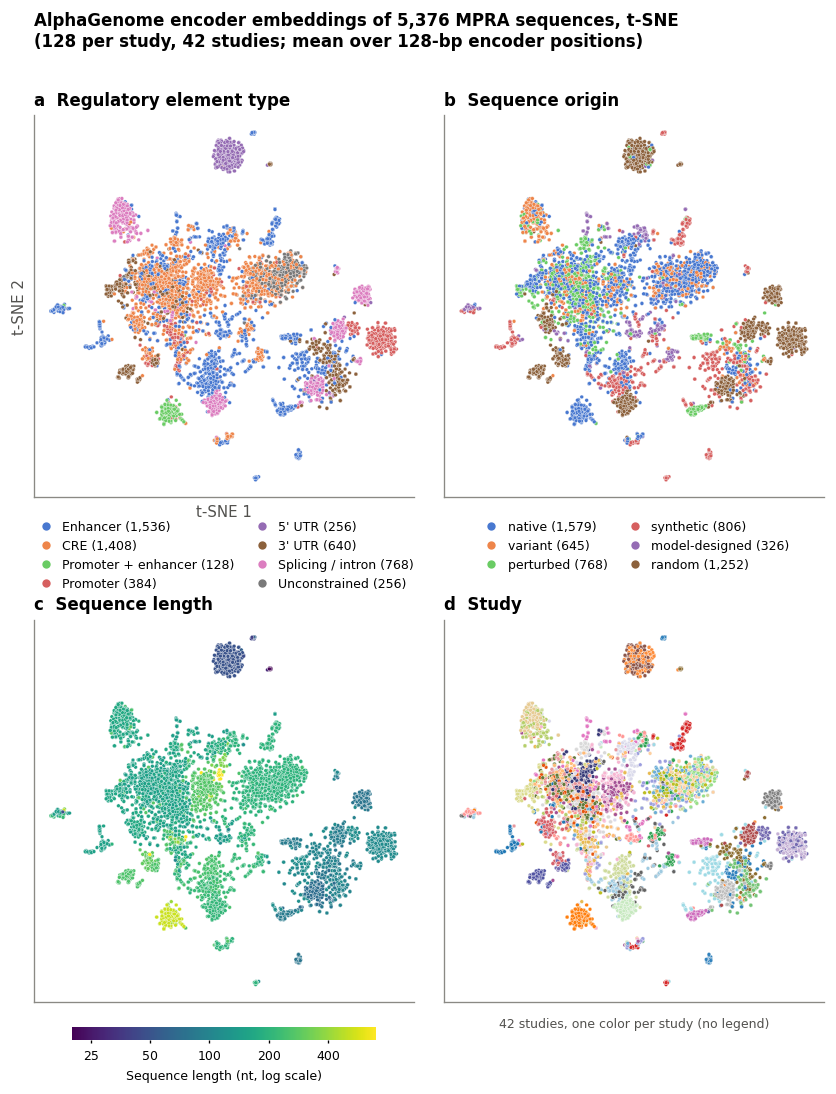

In [17]:
plot_2d("tsne");

*Format (t-SNE and UMAP figures):* all four panels of a figure show the same 2D coordinates, so a cluster can be
compared between the labelings. Legend entries give the number of sequences in each category. Colors in panels a and b
match Figs 1–4 of `mpracollection_stat.ipynb`. Panel c shows how much of the layout follows sequence length; compare it
between `embeddings.npy` and `embeddings_baseline.npy`. Panel d gives each of the 42 studies its own color; there is no
legend because 42 colors cannot be told apart reliably, so the panel only shows whether sequences from the same study
group together, not which study a cluster belongs to.

#### UMAP of the sequence embeddings
UMAP (Uniform Manifold Approximation and Projection) is run on the same 50 principal components as t-SNE, with the
standard settings: 15 nearest neighbors, minimum distance 0.1, Euclidean distance. UMAP keeps more of the global
arrangement than t-SNE, but distances between separate clusters are still only a rough guide. Small groups of very
similar sequences that are not connected to the rest are placed far from the main clusters and drawn as tight clumps,
so a dot far from the rest is usually many overlapping points (for the AlphaGenome encoder embeddings, 13–39 sequences,
mostly from a single study).

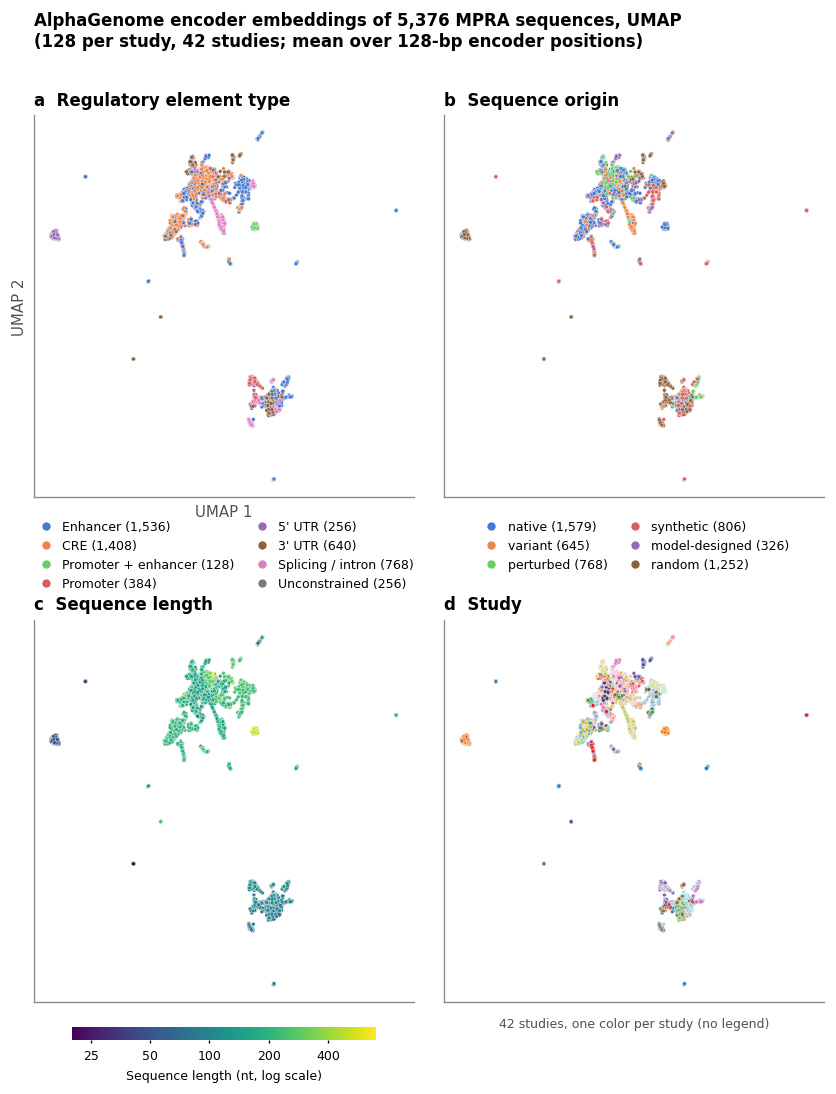

In [18]:
# compatibility_layout=True keeps the standard UMAP layout of umap-learn <= 0.5 (and silences the warning that the
# default will change in a future release)
xy = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1, metric="euclidean", random_state=0, n_jobs=1,
               compatibility_layout=True).fit_transform(x_pca)
seqs["umap1"], seqs["umap2"] = xy[:, 0], xy[:, 1]
plot_2d("umap");